<a href="https://colab.research.google.com/github/isuru-phi6/ionospheric_plasma_bubbles/blob/main/EPB_SriLanka_Swarm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installs the Python client for VirES, ESA’s server for Swarm data. It also brings in cdflib, netCDF4 and cftime, which are needed to read the satellite file formats.

In [ ]:
!python -m pip install viresclient

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 22.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 28.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [viresclient]


In [6]:
%pip install --upgrade viresclient

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 30.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 37.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [viresclient]




*   os, time, warnings, Path: file and folder handling.
*   numpy, pandas: numerical work and tables.
*   matplotlib: plotting.
*   requests: downloads the OMNI files later.
*   tqdm.auto: progress bars.
*   proportion_confint from statsmodels: confidence intervals for proportions, such as the bubble occurrence rate with error bars. It isn’t used yet in this notebook, so it’s probably meant for the later O1 climatology section.
*   warnings.filterwarnings(... FutureWarning) hides pandas deprecation noise.
*   pd.set_option("display.max_columns", 50) shows up to 50 columns when printing tables.
*   plt.rcParams.update(...) sets a light grid and figure resolution for all plots.











In [7]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from tqdm.auto import tqdm
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Packages loaded.")

Packages loaded.


* It tries to mount Google Drive. If that works, everything is saved in MyDrive/EPB_SriLanka, so data survives after Colab disconnects.

* It creates four subfolders:
  1. raw_ibi: raw Swarm files
  2. omni: OMNI files
  3. results: processed tables
  4. figures: plots

* savefig(name) is a small helper that saves the current plot as a 300 dpi PNG in figures/, which is suitable for publication.

In [8]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/EPB_SriLanka")
except ImportError:                       # running outside Colab (e.g. your laptop)
    BASE_DIR = Path(os.environ.get("EPB_DIR", "EPB_SriLanka"))

RAW_DIR  = BASE_DIR / "raw_ibi"
OMNI_DIR = BASE_DIR / "omni"
RES_DIR  = BASE_DIR / "results"
FIG_DIR  = BASE_DIR / "figures"
for d in [RAW_DIR, OMNI_DIR, RES_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print("Working folder:", BASE_DIR)

def savefig(name):
    # Save the current figure to Drive (300 dpi, good for journals)
    plt.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working folder: /content/drive/MyDrive/EPB_SriLanka



These are the choices from your proposal. Change them here only, and every later cell follows.

- **Region:** geographic longitude 70–90°E, latitude ±20°.
- **Period:** January 2014 up to the start of the current month.
- **Satellites:** Swarm A, B and C. A and C fly side by side (about 1.4° apart in longitude), so they often see the *same* bubble at the same time. Keep both for climatology, but remember that their passes are not fully independent.
- `GAP_SECONDS`: a time gap longer than this starts a new pass.
- `MIN_VALID_SAMPLES`: a pass needs at least this many usable seconds of IBI. A full crossing of ±20° latitude takes about 10 minutes (about 600 samples).

In [9]:
LON_MIN, LON_MAX = 70, 90
LAT_MIN, LAT_MAX = -20, 20
START = pd.Timestamp("2014-01-01")
END   = pd.Timestamp.today().normalize().replace(day=1)   # first day of this month
SATELLITES = ["A", "B", "C"]

GAP_SECONDS       = 60
MIN_VALID_SAMPLES = 300
MAX_ABS_QDLAT_AT_CROSSING = 3   # pass must actually cross the magnetic (dip) equator

TRAIN_END_YEAR  = 2022   # train on 2014–2022
TEST_START_YEAR = 2023   # test on 2023–present (Cycle 25 maximum)

TEST_MODE = False        # True = download only 2 months, to check the setup works
if TEST_MODE:
    START, END = pd.Timestamp("2015-03-01"), pd.Timestamp("2015-05-01")

MONTHS = pd.date_range(START, END, freq="MS", inclusive="left")
print(f"{len(MONTHS)} months x {len(SATELLITES)} satellites = {len(MONTHS)*len(SATELLITES)} download jobs")

154 months x 3 satellites = 462 download jobs


##VirES access token


In [10]:
from getpass import getpass
VIRES_URL = "https://vires.services/ows"
VIRES_TOKEN = None

def get_token():
    global VIRES_TOKEN
    if VIRES_TOKEN is None:
        VIRES_TOKEN = getpass("Paste your VirES token and press Enter: ").strip()
    return VIRES_TOKEN

def raw_file(sat, month):
    return RAW_DIR / f"IBI_{sat}_{month:%Y_%m}.parquet"

missing = [(s, m) for m in MONTHS for s in SATELLITES if not raw_file(s, m).exists()]
print(f"{len(missing)} monthly files still to download.")
if missing:
    get_token()

0 monthly files still to download.


Download Swarm IBI data (month by month)
**What is downloaded.** For each satellite and month we ask VirES for all 1-second IBI records inside the box 70-90°E, ±20°, with these variables:

| Variable | Meaning |
|---|---|
| `Bubble_Index` | **1** = bubble, **0** = no bubble, **-1** = could not be analysed (data problem) |
| `Bubble_Probability` | How confident the IBI algorithm is (0-1) |
| `Flags_Bubble` | Quality flag of the bubble detection |
| `QDLat`, `MLT` | Quasi-dipole magnetic latitude and magnetic local time |
| `Kp`, `Dst`, `F107`, `F107_avg81d` | Geomagnetic indices and solar flux, attached by VirES for each second |
| `Radius` (automatic) | Distance from Earth's centre, used for satellite altitude |

**Why month by month?** Each month is saved as one small file. If Colab disconnects, only the current month is lost. Re-run this cell and it continues.

**Time needed:** roughly 20-60 s per file, so a few hours for all 150+ months × 3 satellites. You can run it in pieces over several days.

In [11]:
from viresclient import SwarmRequest

IBI_MEASUREMENTS = ["Bubble_Index", "Bubble_Probability", "Flags_Bubble"]
IBI_AUXILIARIES  = ["QDLat", "MLT", "Kp", "Dst", "F107", "F107_avg81d"]

def download_month(sat, month):
    out = raw_file(sat, month)
    if out.exists():
        return "cached"
    req = SwarmRequest(VIRES_URL, token=get_token())
    req.set_collection(f"SW_OPER_IBI{sat}TMS_2F")
    req.set_products(measurements=IBI_MEASUREMENTS, auxiliaries=IBI_AUXILIARIES)
    req.set_range_filter("Longitude", LON_MIN, LON_MAX)
    req.set_range_filter("Latitude", LAT_MIN, LAT_MAX)
    data = req.get_between(month, month + pd.offsets.MonthBegin(1), show_progress=False)
    df = data.as_dataframe()
    # store as float32 to halve the file size
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")
    df.to_parquet(out)
    return f"{len(df):,} rows"

failed = []
for month in tqdm(MONTHS, desc="months"):
    for sat in SATELLITES:
        try:
            msg = download_month(sat, month)
        except Exception as e:                 # no data that month, network error, etc.
            msg = f"FAILED ({type(e).__name__}: {str(e)[:80]})"
            failed.append((sat, month))
        if msg != "cached":
            print(f"Swarm {sat} {month:%Y-%m}: {msg}")
print("Done. Failed jobs:", len(failed), "(re-run this cell to retry them)")

months:   0%|          | 0/154 [00:00<?, ?it/s]

Done. Failed jobs: 0 (re-run this cell to retry them)


In [13]:
example = sorted(RAW_DIR.glob("IBI_*.parquet"))[0]
raw_example = pd.read_parquet(example)
print(example.name, raw_example.shape)
display(raw_example.head())
print("\nBubble_Index counts:\n", raw_example["Bubble_Index"].value_counts())

IBI_A_2014_01.parquet (18471, 13)


,QDLat,Bubble_Probability,Flags_Bubble,Kp,F107_avg81d,Dst,Latitude,Spacecraft,Radius,MLT,F107,Longitude,Bubble_Index
Timestamp,,,,,,,,,,,,,
2014-01-01 05:25:30,-30.314989,0.0,32,1.333,151.921295,-3.775000,-19.973948,A,6876237.5,10.800801,150.920502,83.267052,-1
2014-01-01 05:25:31,-30.246136,0.0,32,1.333,151.921295,-3.775833,-19.910568,A,6876231.5,10.801905,150.920654,83.265938,-1
2014-01-01 05:25:32,-30.177275,0.0,32,1.333,151.921295,-3.776667,-19.847189,A,6876226.0,10.803004,150.920822,83.264824,-1
2014-01-01 05:25:33,-30.108406,0.0,32,1.333,151.921295,-3.777500,-19.783810,A,6876220.5,10.804100,150.920990,83.263702,-1
2014-01-01 05:25:34,-30.039530,0.0,32,1.333,151.921310,-3.778333,-19.720430,A,6876215.0,10.805192,150.921158,83.262581,-1



Bubble_Index counts:
 Bubble_Index
-1    9463
 0    9008
Name: count, dtype: int64


---
## OMNI hourly data (solar wind and geomagnetic indices)
NASA's OMNI dataset provides **hourly** values for the whole period in one file per year. We use it for drivers that need **time history**, which the IBI files cannot provide:

| OMNI variable | Why it matters for bubbles |
|---|---|
| IMF **Bz** (GSM) | Southward Bz (negative) lets solar-wind electric fields *penetrate* to the equator (prompt penetration) |
| Solar wind speed **V** | Stronger driving of the magnetosphere |
| **Dst** | Storm intensity (ring current). Its minimum over the past 24 h captures the delayed *disturbance dynamo* |
| **AE** | Auroral activity. Heating at high latitudes drives the disturbance dynamo hours later |

Missing values in OMNI are written as 999.9, 9999 and so on, and the code turns them into `NaN` (not a number). **AE is sometimes missing for recent years** (Kyoto releases it late). The code checks this later and drops AE automatically if too much is missing.

In [14]:
OMNI_URL = "https://spdf.gsfc.nasa.gov/pub/data/omni/low_res_omni/omni2_{year}.dat"
this_year = pd.Timestamp.today().year

for year in range(START.year - 1, END.year + 1):     # one extra year before START for lags
    out = OMNI_DIR / f"omni2_{year}.dat"
    if out.exists() and year < this_year:
        continue                                       # past years never change
    try:
        r = requests.get(OMNI_URL.format(year=year), timeout=120)
        r.raise_for_status()
        out.write_bytes(r.content)
        print("downloaded", out.name)
    except Exception as e:
        print(f"Could not download {year}: {e}" + (" (keeping old copy)" if out.exists() else ""))

# Word positions from the OMNI2 format description (0-based column index)
OMNI_COLS = {0: "year", 1: "doy", 2: "hour", 16: "Bz", 23: "Np", 24: "V",
             38: "Kp10", 40: "Dst", 41: "AE", 50: "F107_omni", 52: "AL", 53: "AU"}
FILL = {"Bz": 999, "Np": 999, "V": 9999, "Kp10": 99, "Dst": 99999,
        "AE": 9999, "F107_omni": 999, "AL": 99999, "AU": 99999}

frames = []
for f in sorted(OMNI_DIR.glob("omni2_*.dat")):
    d = pd.read_csv(f, sep=r"\s+", header=None, usecols=list(OMNI_COLS)).rename(columns=OMNI_COLS)
    frames.append(d)
omni = pd.concat(frames, ignore_index=True)
omni.index = (pd.to_datetime(omni["year"].astype(str), format="%Y")
              + pd.to_timedelta(omni["doy"] - 1, unit="D")
              + pd.to_timedelta(omni["hour"], unit="h"))
for col, fill in FILL.items():
    omni.loc[omni[col].abs() >= fill, col] = np.nan
omni = omni.drop(columns=["year", "doy", "hour"]).sort_index()
omni = omni[~omni.index.duplicated()]
print(omni.index.min(), "to", omni.index.max())
print("Fraction missing per variable:\n", omni.isna().mean().round(3))

downloaded omni2_2026.dat
2013-01-01 00:00:00 to 2026-12-31 23:00:00
Fraction missing per variable:
 Bz           0.021
Np           0.025
V            0.022
Kp10         0.012
Dst          0.012
AE           0.014
F107_omni    0.013
AL           0.014
AU           0.014
dtype: float64


**Building driver history features.** For every hour *t* we compute values that describe what happened *before* that hour. Bubbles respond to electric fields with delays from minutes to about a day:
- `Bz_lag1`: Bz one hour earlier. `Bz_mean3h`: average Bz over the previous 3 hours.
- `V_lag1`: solar wind speed one hour earlier.
- `Dst_min24`: lowest Dst in the last 24 h (how strong a recent storm was).
- `dDst_3h`: change of Dst over 3 h (negative = storm main phase in progress).
- `AE_max6h`: highest AE in the last 6 h.

In [15]:
omni_feat = pd.DataFrame(index=omni.index)
omni_feat["Dst_omni"]  = omni["Dst"]
omni_feat["Dst_min24"] = omni["Dst"].rolling(24, min_periods=12).min()
omni_feat["dDst_3h"]   = omni["Dst"] - omni["Dst"].shift(3)
omni_feat["AE"]        = omni["AE"]
omni_feat["AE_max6h"]  = omni["AE"].rolling(6, min_periods=3).max()
omni_feat["Bz_lag1"]   = omni["Bz"].shift(1)
omni_feat["Bz_mean3h"] = omni["Bz"].shift(1).rolling(3, min_periods=2).mean()
omni_feat["V_lag1"]    = omni["V"].shift(1)
omni_feat.describe().round(1)

,Dst_omni,Dst_min24,dDst_3h,AE,AE_max6h,Bz_lag1,Bz_mean3h,V_lag1
count,121215.0,121216.0,121212.0,120936.0,120937.0,120134.0,120141.0,120059.0
mean,-11.2,-23.7,0.0,177.4,298.7,-0.1,-0.1,423.7
std,18.6,23.7,8.5,192.0,252.9,3.0,2.6,95.2
min,-406.0,-406.0,-244.0,4.0,9.0,-42.2,-36.4,251.0
25%,-19.0,-31.0,-3.0,49.0,100.0,-1.6,-1.4,352.0
50%,-8.0,-19.0,1.0,99.0,222.0,-0.1,-0.1,403.0
75%,0.0,-9.0,4.0,238.0,430.0,1.4,1.2,476.0
max,71.0,19.0,96.0,2597.0,2597.0,58.9,56.6,1121.0


---
## Build the pass-level dataset (one row per pass)
The raw data has about 1 row per second. A bubble seen at second 100 and again at second 101 is the *same* bubble, so treating each second as a separate observation would fake a huge sample size. Reddy et al. used 1-second samples with a random split, which inflates their scores. We reduce every crossing of the region to **one row**:

1. Sort by satellite and time. A gap larger than 60 s → a new pass.
2. For each pass compute:
   - `bubble` = 1 if **any** second has `Bubble_Index = 1` (this is the target)
   - `n_valid` = number of usable seconds (`Bubble_Index` 0 or 1), and `max_prob`
   - time, longitude and local time at the **dip-equator crossing** (where |QDLat| is smallest)
   - satellite altitude (Swarm B flies about 60 km higher than A and C, which matters for bubble detection)
   - Kp, F10.7 and its 81-day average at the crossing
3. Keep only **night passes** (local time 18:00–06:00) with enough valid data.

Local time is computed as **LT = UT + longitude/15** (hours). At 80°E that is UT + 5 h 20 min, which is Sri Lanka's clock time.

In [16]:
def month_to_passes(df):
    # Reduce one month of 1-second IBI records to one row per satellite pass
    if df.empty:
        return pd.DataFrame()
    d = df.reset_index().rename(columns={"index": "Timestamp"})
    d = d.dropna(subset=["QDLat"]).sort_values(["Spacecraft", "Timestamp"])
    d["absQD"]   = d["QDLat"].abs()
    d["valid"]   = d["Bubble_Index"].isin([0, 1])
    d["is_bub"]  = d["Bubble_Index"] == 1
    d["prob_ok"] = d["Bubble_Probability"].where(d["valid"])
    d["alt_km"]  = d["Radius"] / 1000 - 6371.2

    new_pass = (d["Spacecraft"] != d["Spacecraft"].shift()) | \
               (d["Timestamp"].diff() > pd.Timedelta(seconds=GAP_SECONDS))
    d["pass_id"] = new_pass.cumsum()
    g = d.groupby("pass_id")

    summary = g.agg(sat=("Spacecraft", "first"),
                    t_start=("Timestamp", "first"), t_end=("Timestamp", "last"),
                    n_samples=("Timestamp", "size"), n_valid=("valid", "sum"),
                    n_bubble=("is_bub", "sum"), max_prob=("prob_ok", "max"),
                    alt_km=("alt_km", "mean"))
    # values at the dip-equator crossing (row with smallest |QDLat|)
    eq_rows = d.loc[g["absQD"].idxmin()].set_index("pass_id")
    eq = eq_rows[["Timestamp", "Longitude", "Latitude", "absQD", "MLT",
                  "Kp", "Dst", "F107", "F107_avg81d"]]
    eq.columns = ["t_eq", "lon_eq", "lat_eq", "absQD_eq", "MLT_eq",
                  "Kp", "Dst_vires", "F107", "F107_81"]
    return summary.join(eq)

files = sorted(RAW_DIR.glob("IBI_*.parquet"))
passes = pd.concat([month_to_passes(pd.read_parquet(f)) for f in tqdm(files, desc="files")],
                   ignore_index=True)
print(f"{len(passes):,} passes in total (day and night)")

files:   0%|          | 0/462 [00:00<?, ?it/s]

24,704 passes in total (day and night)


In [ ]:
p = passes.copy()
p["t_eq"]  = pd.to_datetime(p["t_eq"])
ut_hours   = p["t_eq"].dt.hour + p["t_eq"].dt.minute / 60 + p["t_eq"].dt.second / 3600
p["LT"]    = (ut_hours + p["lon_eq"] / 15) % 24
p["bubble"] = (p["n_bubble"] > 0).astype(int)

keep = (((p["LT"] >= 18) | (p["LT"] < 6))
        & (p["n_valid"] >= MIN_VALID_SAMPLES)
        & (p["absQD_eq"] <= MAX_ABS_QDLAT_AT_CROSSING))
print(f"Night passes with enough data: {keep.sum():,} of {len(p):,}")
p = p[keep].sort_values("t_eq").reset_index(drop=True)

# calendar features
p["year"]  = p["t_eq"].dt.year
p["month"] = p["t_eq"].dt.month
p["doy"]   = p["t_eq"].dt.dayofyear
p["LT_from18"] = (p["LT"] - 18) % 24          # 0 = 18 LT ... 12 = 06 LT (easy to plot)

# Cyclic encoding: 23 LT and 0 LT are neighbours, but as plain numbers they look 23 apart.
# Putting a cyclic variable on a circle (sin, cos) fixes that for the models.
p["LT_sin"]  = np.sin(2 * np.pi * p["LT"] / 24)
p["LT_cos"]  = np.cos(2 * np.pi * p["LT"] / 24)
p["doy_sin"] = np.sin(2 * np.pi * p["doy"] / 365.25)
p["doy_cos"] = np.cos(2 * np.pi * p["doy"] / 365.25)

# solar-cycle period labels used in O1
p["period"] = pd.cut(p["year"], bins=[2013, 2019, 2022, 2100],
                     labels=["C24 decline (2014-19)", "C25 rise (2020-22)", "C25 maximum (2023-)"])

# attach the OMNI history features at the hour of the equator crossing
hour = p["t_eq"].dt.floor("h")
p = p.join(omni_feat.reindex(hour).reset_index(drop=True))
p["Dst"] = p["Dst_omni"].fillna(p["Dst_vires"])     # OMNI first, VirES as backup

p.to_parquet(RES_DIR / "passes_night.parquet")
p.to_csv(RES_DIR / "passes_night.csv", index=False)
print("Saved", len(p), "night passes.  Overall bubble rate:", round(p["bubble"].mean(), 3))
display(p.head())

Night passes with enough data: 11,638 of 24,704
Saved 11638 night passes.  Overall bubble rate: 0.062


,sat,t_start,t_end,n_samples,n_valid,n_bubble,max_prob,alt_km,t_eq,lon_eq,lat_eq,absQD_eq,MLT_eq,Kp,Dst_vires,F107,F107_81,LT,bubble,year,month,doy,LT_from18,LT_sin,LT_cos,doy_sin,doy_cos,period,Dst_omni,Dst_min24,dDst_3h,AE,AE_max6h,Bz_lag1,Bz_mean3h,V_lag1,Dst
0,A,2014-01-01 17:14:45,2014-01-01 17:25:16,632,632,0,0.0,506.715881,2014-01-01 17:18:00,85.056892,7.630787,0.014565,22.905510,3.000,-28.000000,157.996017,152.045303,22.970459,0,2014,1,1,4.970459,-0.266281,0.963895,0.017202,0.999852,C24 decline (2014-19),-27.0,-39.0,5.0,153.0,881.0,3.3,1.400000,522.0,-27.0
1,C,2014-01-01 17:16:40,2014-01-01 17:27:11,632,632,0,0.0,506.937836,2014-01-01 17:19:55,84.578537,7.623678,0.016070,22.903942,3.000,-27.840279,158.015045,152.045639,22.970514,0,2014,1,1,4.970514,-0.266268,0.963899,0.017202,0.999852,C24 decline (2014-19),-27.0,-39.0,5.0,153.0,881.0,3.3,1.400000,522.0,-27.0
2,B,2014-01-02 16:52:18,2014-01-02 17:02:49,632,632,0,0.0,506.457184,2014-01-02 16:55:33,89.376175,7.636949,0.023436,22.830761,3.333,-21.445000,160.385025,152.398026,22.884245,0,2014,1,2,4.884245,-0.287968,0.957640,0.034398,0.999408,C24 decline (2014-19),-24.0,-27.0,-4.0,303.0,516.0,-1.6,-0.966667,527.0,-24.0
3,A,2014-01-02 16:53:23,2014-01-02 17:03:53,631,631,0,0.0,506.444244,2014-01-02 16:56:37,89.108200,7.670012,0.013673,22.829884,3.333,-21.338333,160.385681,152.398300,22.884158,0,2014,1,2,4.884158,-0.287990,0.957634,0.034398,0.999408,C24 decline (2014-19),-24.0,-27.0,-4.0,303.0,516.0,-1.6,-0.966667,527.0,-24.0
4,C,2014-01-02 16:55:21,2014-01-02 17:05:51,631,631,0,0.0,506.658020,2014-01-02 16:58:35,88.617126,7.668026,0.013595,22.828356,3.333,-21.141666,160.386917,152.398804,22.884197,0,2014,1,2,4.884197,-0.287980,0.957637,0.034398,0.999408,C24 decline (2014-19),-24.0,-27.0,-4.0,303.0,516.0,-1.6,-0.966667,527.0,-24.0


**Check before moving on:**
- How many night passes per year and per satellite? There should be a few hundred per satellite per year.
- Does the bubble rate change with year? It should be low around 2018–2020 (solar minimum) and high in 2014 and 2023–2025.

sat      A     B     C    All
year                         
2014   287   288   287    862
2015   304   296   306    906
2016   322   298   315    935
2017   301   300   307    908
2018   307   296   304    907
2019   310   304   304    918
2020   295   305   314    914
2021   297   302   300    899
2022   296   299   305    900
2023   299   302   304    905
2024   305   300   301    906
2025   308   306   301    915
2026   262   248   253    763
All   3893  3844  3901  11638


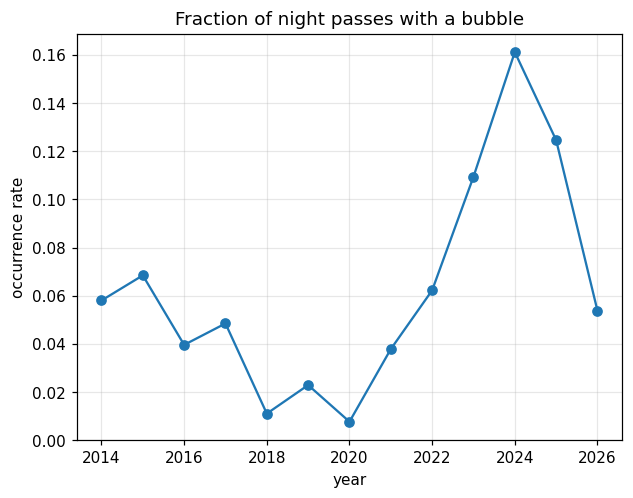

In [ ]:
print(pd.crosstab(p["year"], p["sat"], margins=True))
p.groupby("year")["bubble"].mean().plot(marker="o", title="Fraction of night passes with a bubble")
plt.ylabel("occurrence rate"); savefig("rate_by_year"); plt.show()

---
## (optional): Look at a few bubbles in the raw plasma density
A real bubble is a sharp **bite-out** (sudden drop) in electron density *Ne*. This cell downloads Langmuir-probe density for a few bubble passes and one quiet pass and plots them. Bubble seconds are marked in red. It is a good sanity check and gives you Figure 1 for the paper (like Reddy et al. Fig. 1).

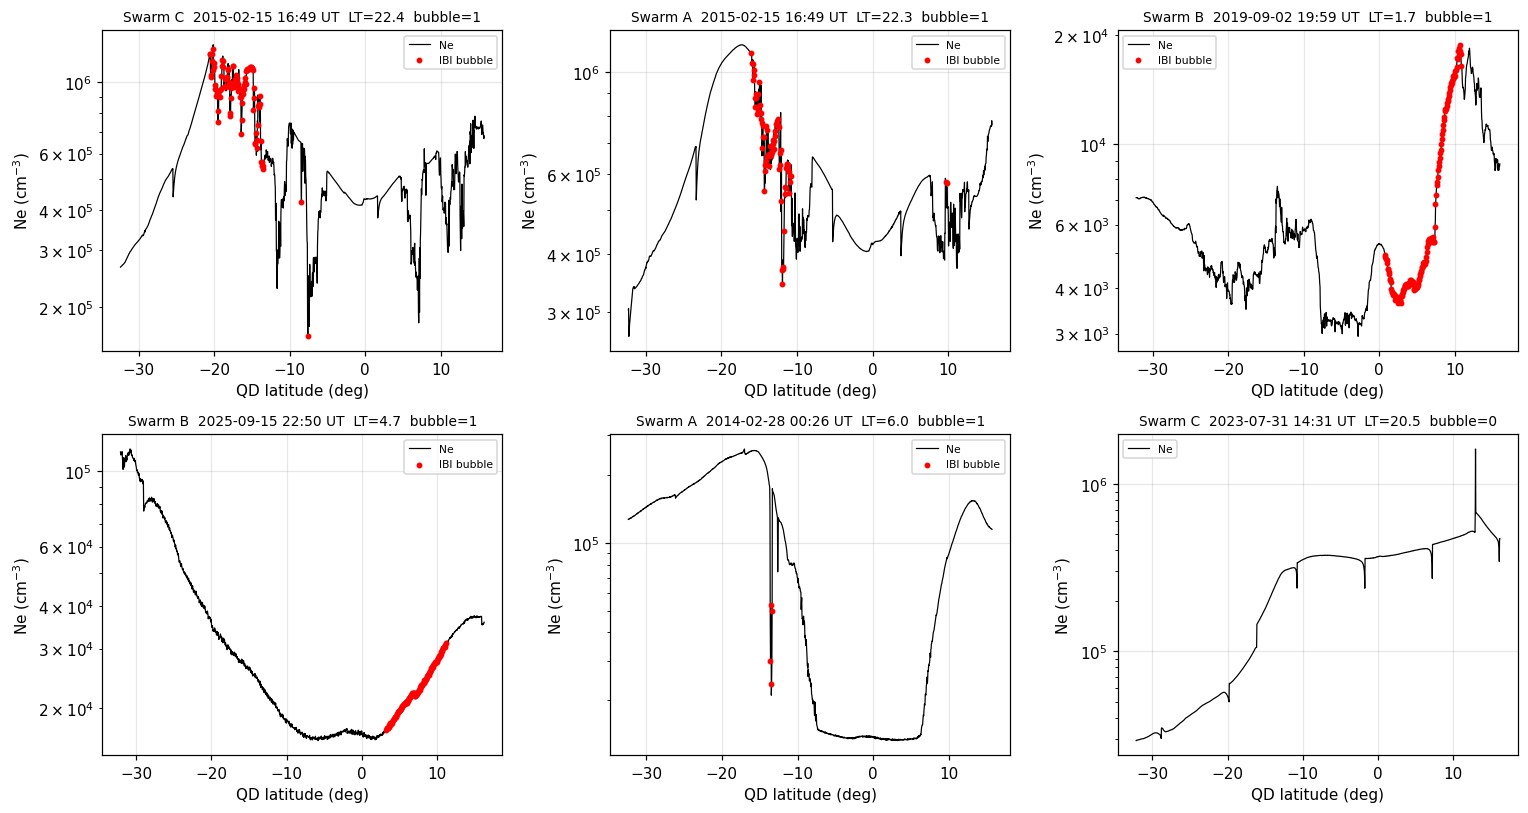

In [ ]:
def get_density_name(req):
    # viresclient >= 0.12 calls Langmuir-probe density 'N_elec'; older versions used 'Ne'
    names = req.available_measurements("EFI")
    return "N_elec" if "N_elec" in names else "Ne"

def plot_pass(row, ax):
    pad = pd.Timedelta(seconds=30)
    t0, t1 = pd.Timestamp(row.t_start) - pad, pd.Timestamp(row.t_end) + pad
    # 1) plasma density from the Langmuir probe (2 samples per second)
    req = SwarmRequest(VIRES_URL, token=get_token())
    req.set_collection(f"SW_OPER_EFI{row.sat}_LP_1B")
    ne_name = get_density_name(req)
    req.set_products(measurements=[ne_name], auxiliaries=["QDLat"])
    ne = req.get_between(t0.to_pydatetime(), t1.to_pydatetime(), show_progress=False).as_dataframe()
    # 2) IBI flags for the same pass
    req = SwarmRequest(VIRES_URL, token=get_token())
    req.set_collection(f"SW_OPER_IBI{row.sat}TMS_2F")
    req.set_products(measurements=["Bubble_Index"], auxiliaries=["QDLat"])
    ibi = req.get_between(t0.to_pydatetime(), t1.to_pydatetime(), show_progress=False).as_dataframe()
    if ne.empty:
        raise ValueError("no density data for this pass")
    ne = ne[ne[ne_name] > 0].sort_index()                    # log axis needs positive values
    ax.semilogy(ne["QDLat"], ne[ne_name], lw=0.8, color="k", label="Ne")
    bub = ibi[ibi["Bubble_Index"] == 1]
    if len(bub):
        ne_at_bub = ne[ne_name].reindex(bub.index, method="nearest", tolerance=pd.Timedelta("1s"))
        ax.scatter(bub["QDLat"], ne_at_bub, s=8, color="red", zorder=3, label="IBI bubble")
    ax.set_title(f"Swarm {row.sat}  {row.t_eq:%Y-%m-%d %H:%M} UT  LT={row.LT:.1f}  bubble={row.bubble}", fontsize=9)
    ax.set_xlabel("QD latitude (deg)"); ax.set_ylabel("Ne (cm$^{-3}$)"); ax.legend(fontsize=7)

RUN_DENSITY_CHECK = True
if RUN_DENSITY_CHECK:
    examples = pd.concat([p[p.bubble == 1].sample(5, random_state=1),
                          p[p.bubble == 0].sample(1, random_state=1)])
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
    for row, ax in zip(examples.itertuples(), axes.ravel()):
        try:
            plot_pass(row, ax)
        except Exception as e:
            print(f"Swarm {row.sat} {row.t_eq}: {type(e).__name__}: {e}")   # show the real reason
            ax.set_title(f"failed: {str(e)[:60]}", fontsize=7)
    plt.tight_layout(); savefig("example_passes_Ne"); plt.show()